In [1]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [1]:
import pandas as pd

In [4]:
data = pd.read_csv('../dataset.csv')

In [ ]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
207,190,"airport_name, airport_elevation",airport_iata_code,mondialjoin.csv,False,True,False
208,191,"city_elevation, airport_name",airport_iata_code,mondialjoin.csv,False,True,False
209,192,"airport_name, language_percentage, city_name",airport_iata_code,mondialjoin.csv,False,True,False
210,193,airport_latitude,airport_longitude,mondialjoin.csv,False,True,False


In [10]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("all-MiniLM-L6-v2")


In [13]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = model.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[1.         0.6606377  0.16261399]
 [0.6606377  1.         0.2098045 ]
 [0.16261399 0.2098045  1.        ]]


In [16]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [20]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = model.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [24]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [22]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

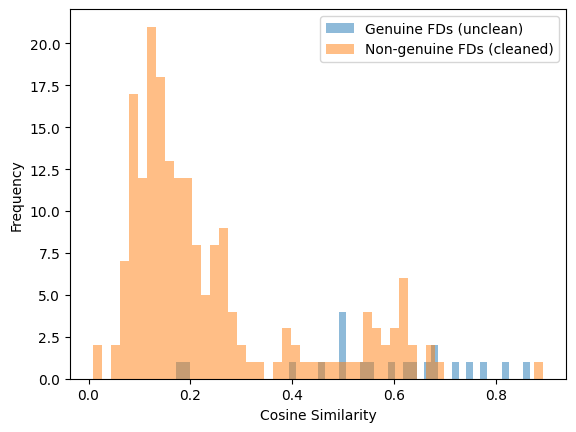

In [27]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [33]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [41]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = model.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [42]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [49]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
    return min_distance

In [52]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

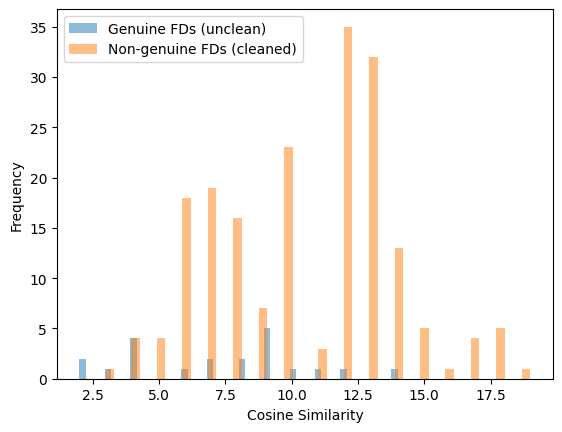

In [54]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [56]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [57]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance > max_distance:
            max_distance = distance
    return max_distance

In [ ]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

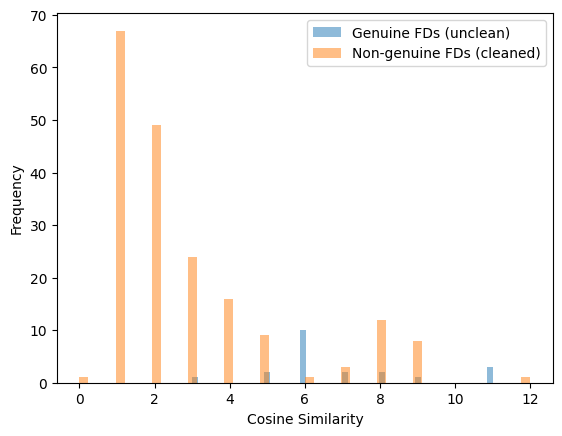

In [59]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [64]:
df = pd.DataFrame()

In [65]:
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

In [66]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,6,2,True
1,0.640750,6,9,True
2,0.620726,6,2,True
3,0.503650,6,9,True
4,0.191531,3,14,True
...,...,...,...,...
207,0.613061,8,7,False
208,0.562231,8,7,False
209,0.559326,8,7,False
210,0.893999,9,3,False


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [69]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)

In [70]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8604651162790697
              precision    recall  f1-score   support

       False       0.92      0.92      0.92        39
        True       0.25      0.25      0.25         4

    accuracy                           0.86        43
   macro avg       0.59      0.59      0.59        43
weighted avg       0.86      0.86      0.86        43



In [71]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


cosine_sim    0.640481
leven         0.189566
lcs           0.169953
dtype: float64


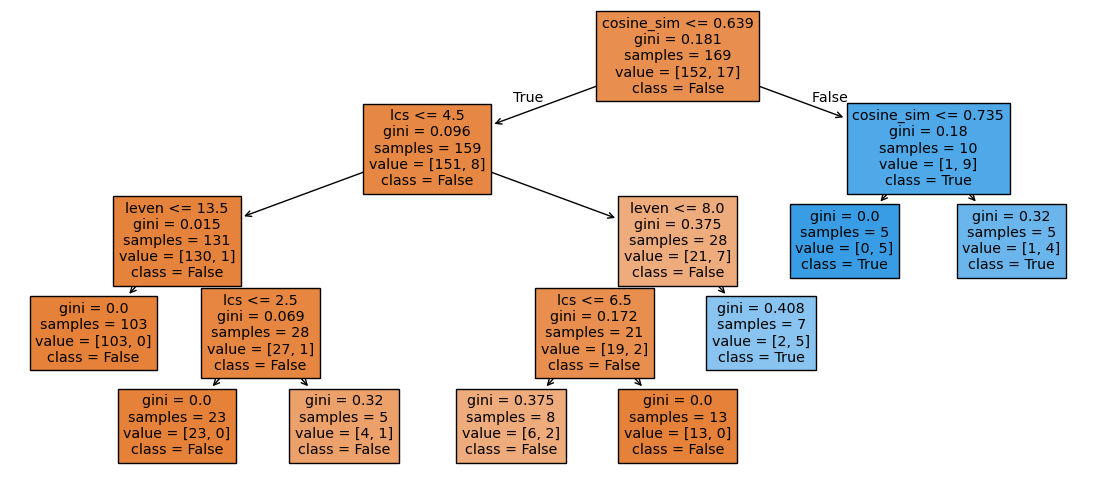

In [72]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [75]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [76]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [77]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7209302325581395
              precision    recall  f1-score   support

       False       1.00      0.69      0.82        39
        True       0.25      1.00      0.40         4

    accuracy                           0.72        43
   macro avg       0.62      0.85      0.61        43
weighted avg       0.93      0.72      0.78        43



In [78]:
y_pred

array([False, False, False, False,  True,  True, False, False,  True,
       False, False, False,  True, False, False,  True,  True, False,
       False, False, False, False,  True, False, False, False, False,
        True,  True, False,  True,  True, False, False,  True,  True,
       False, False,  True, False,  True,  True, False])